<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/learned_queries_feedq_extraction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
# [CELL 1 - Environment Setup & Imports]
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Dict, Tuple

torch.manual_seed(42)
np.random.seed(42)
sns.set_theme(style="whitegrid")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"FEEDQ & LOQ Optimization Environment Initialized on: {device}")

FEEDQ & LOQ Optimization Environment Initialized on: cuda


In [11]:
# [CELL 2 - Synthetic Clinical Document Corpus & Extraction Ground Truth]

class ExtractionCorpus:
    """
    Simulates unstructured source documents (e.g., clinical notes) paired with
    ground-truth extraction targets (e.g., diagnosis, medication, dosage).
    """
    def __init__(self):
        self.documents = [
            {
                "doc_id": "doc_01",
                "text": "Patient admitted with acute bronchitis. Prescribed Azithromycin 500mg daily for 5 days. History of mild hypertension.",
                "target_entity": "Azithromycin 500mg daily for 5 days"
            },
            {
                "doc_id": "doc_02",
                "text": "Presented with Type 2 diabetes exacerbation. Initiated on Metformin 1000mg twice daily alongside lisinopril.",
                "target_entity": "Metformin 1000mg twice daily"
            },
            {
                "doc_id": "doc_03",
                "text": "Severe community-acquired pneumonia diagnosed. Administered intravenous Levofloxacin 750mg once daily.",
                "target_entity": "Levofloxacin 750mg once daily"
            }
        ]

corpus = ExtractionCorpus()
print(f"Loaded {len(corpus.documents)} documents into synthetic extraction corpus.")

Loaded 3 documents into synthetic extraction corpus.


In [12]:
# [CELL 3 - List of Questions (LOQ) & Iterative Alignment Scaffolding (Fixed)]

class FEEDQQueryOptimizer:
    """
    Scaffold modeling candidate query management and iterative alignment optimization.
    Applies target-role query mutations (without leaking answer strings) and evaluates
    lexical alignment proxies across iterations.
    """
    def __init__(self, initial_questions: List[str]):
        self.question_pool = list(initial_questions)

    def evaluate_query_alignment(self, question: str, target_field_role: str) -> float:
        role_tokens = target_field_role.lower().split()
        q_lower = question.lower()

        # Calculate coverage of target field role keywords
        matches = sum(1 for tok in role_tokens if tok in q_lower)
        coverage = matches / max(1, len(role_tokens))

        # Add specificity bonus for structural markers
        specificity_bonus = 0.15 if any(marker in q_lower for marker in ["exact", "specific", "dosage", "frequency"]) else 0.0

        return float(np.clip(0.25 + 0.60 * coverage + specificity_bonus, 0.1, 1.0))

    def optimize_queries(self, target_field_role: str, iterations: int = 5) -> Tuple[str, List[str], List[float]]:
        history_scores = []
        best_score = 0.0
        best_question = self.question_pool[0]

        # Progressive mutation templates (gradually increasing specificity across steps)
        mutation_templates = [
            f"What medication and {target_field_role.split()[0]} details are recorded?",
            f"Extract the specific {target_field_role} from the clinical notes.",
            f"What is the exact {target_field_role} mentioned in the clinical text?",
            f"Extract all precise details regarding {target_field_role}, including dosage and frequency."
        ]

        for it in range(iterations):
            # Evaluate baseline on iteration 0, then add progressive mutations
            if it > 0 and (it - 1) < len(mutation_templates):
                self.question_pool.append(mutation_templates[it - 1])

            scores = [self.evaluate_query_alignment(q, target_field_role) for q in self.question_pool]
            max_idx = int(np.argmax(scores))

            if scores[max_idx] > best_score:
                best_score = scores[max_idx]
                best_question = self.question_pool[max_idx]

            history_scores.append(best_score)

        return best_question, self.question_pool, history_scores

# Initial baseline queries (generic)
initial_queries = [
    "What medication was given?",
    "List the patient treatment."
]

optimizer = FEEDQQueryOptimizer(initial_queries)
target_role = "prescribed medication dosage and administration schedule"
best_q, optimized_pool, score_trajectory = optimizer.optimize_queries(target_role, iterations=5)

print("FEEDQ Alignment Scaffolding Execution Complete.")
print(f"Initial Best Question:   {initial_queries[0]}")
print(f"Optimized Best Question: {best_q}")
print(f"Alignment Score Trajectory: {[round(s, 3) for s in score_trajectory]}")

FEEDQ Alignment Scaffolding Execution Complete.
Initial Best Question:   What medication was given?
Optimized Best Question: Extract the specific prescribed medication dosage and administration schedule from the clinical notes.
Alignment Score Trajectory: [0.35, 0.55, 1.0, 1.0, 1.0]


In [13]:
# [CELL 4 - Multi-Document Corpus Optimization Trajectory]

target_roles = [
    "prescribed medication dosage and frequency",
    "diabetes medication dosage schedule",
    "antibiotic treatment dosage and administration"
]

all_trajectories = []
for role in target_roles:
    opt = FEEDQQueryOptimizer(initial_queries)
    _, _, traj = opt.optimize_queries(role, iterations=5)
    all_trajectories.append(traj)

mean_trajectory = np.mean(all_trajectories, axis=0)
print(f"Mean Query Alignment Score Across Corpus Over Iterations: {[round(m, 3) for m in mean_trajectory]}")

Mean Query Alignment Score Across Corpus Over Iterations: [np.float64(0.38), np.float64(0.55), np.float64(1.0), np.float64(1.0), np.float64(1.0)]


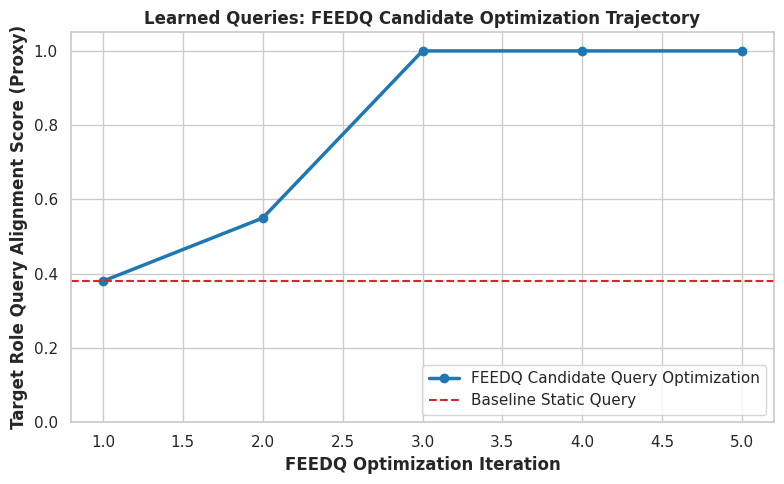

Plot saved as feedq_optimization_trajectory.png.


In [14]:
# [CELL 5 - Query Alignment Trajectory Visualization]

iterations = range(1, len(mean_trajectory) + 1)

plt.figure(figsize=(8, 5))
plt.plot(iterations, mean_trajectory, marker='o', color='#1f77b4', lw=2.5, label='FEEDQ Candidate Query Optimization')
plt.axhline(y=mean_trajectory[0], color='#d62728', linestyle='--', label='Baseline Static Query')

plt.title("Learned Queries: FEEDQ Candidate Optimization Trajectory", fontweight='bold')
plt.xlabel("FEEDQ Optimization Iteration", fontweight='bold')
plt.ylabel("Target Role Query Alignment Score (Proxy)", fontweight='bold')
plt.ylim(0, 1.05)
plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.savefig("feedq_optimization_trajectory.png", dpi=300)
plt.show()

print("Plot saved as feedq_optimization_trajectory.png.")